# 共起ネットワークを描く

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/07_corpus_statistics/cooccurrence_network.ipynb)

NLP クックブック 07-11 ／ コーパスの統計と探索

よく一緒に出てくる単語同士を線で結んだネットワーク図で、テキストの話題の構造を俯瞰したい。

In [1]:
!pip install -q fugashi unidic-lite matplotlib-fontja

In [2]:
import io, re, urllib.request, zipfile
from collections import Counter
from itertools import combinations
from fugashi import Tagger

def aozora(url):
    with urllib.request.urlopen(url) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    text = z.read(z.namelist()[0]).decode("cp932")
    text = re.split(r"-{50,}", text)[2].split("底本：")[0]
    return re.sub(r"《.+?》|［＃.+?］|｜", "", text).replace("\r\n", "\n").strip()

text = aozora("https://www.aozora.gr.jp/cards/000035/files/1567_ruby_4948.zip")  # 走れメロス
tagger = Tagger()
docs = [{w.surface for w in tagger(s) if w.feature.pos1 == "名詞" and w.feature.pos2 in ("普通名詞", "固有名詞") and len(w.surface) > 1}
        for s in re.split(r"[。\n]", text) if s.strip()]
word_count = Counter(w for d in docs for w in d)
pair_count = Counter(p for d in docs for p in combinations(sorted(d), 2))

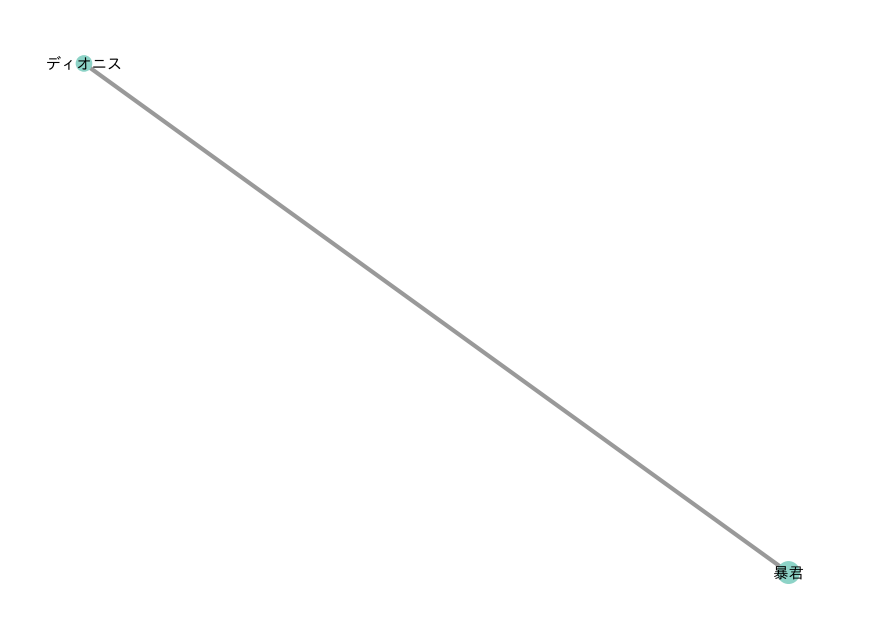

In [3]:
import matplotlib.pyplot as plt
import matplotlib_fontja
import networkx as nx

G = nx.Graph()
for (a, b), c in pair_count.items():
    jaccard = c / (word_count[a] + word_count[b] - c)
    if c >= 3 and jaccard >= 0.1:
        G.add_edge(a, b, weight=jaccard)

communities = nx.community.greedy_modularity_communities(G)  # 色分け用にコミュニティ検出
color = {w: i for i, com in enumerate(communities) for w in com}

plt.figure(figsize=(11, 8))
pos = nx.spring_layout(G, k=0.6, seed=0)
nx.draw_networkx_nodes(G, pos, node_size=[word_count[w] * 40 for w in G], node_color=[color[w] for w in G], cmap="Set3")
nx.draw_networkx_edges(G, pos, width=[G[a][b]["weight"] * 6 for a, b in G.edges], alpha=0.4)
nx.draw_networkx_labels(G, pos, font_family=plt.rcParams["font.family"], font_size=11)
plt.axis("off"); plt.show()

- 線を引く基準は、共起回数の下限と Jaccard 係数の下限の 2 つで調整する。線が多すぎると毛玉になる。
- `draw_networkx_labels` は rcParams のフォントを見ないので `font_family` を明示する。